<div style="background-color:#dbeafe; padding:20px; border-radius:6px;">

<h2>Modelling and Forecasting Volatility in Emerging Markets Using GARCH-Family Models: The Case of Malawi All Share Index</h2>
<hr>

<small>
<b>Authors:</b>&nbsp;
Albert Balakasi <a href="mailto:albsjr50@gmail.com">albsjr50@gmail.com</a>
&nbsp;&bull;&nbsp;
Joel Muchemeranwa <a href="mailto:jmucheme@gmail.com">jmucheme@gmail.com</a>
&nbsp;&bull;&nbsp;
Tobias Owino <a href="mailto:tobiaswino@gmail.com">tobiaswino@gmail.com</a>
</small>

<hr>
CAPSTONE PROJECT<br>

<b>Programme:</b> MSc Financial Engineering<br>
<b>Institution:</b> WorldQuant University<br>
<b>Date:</b> October 2026<br>
<b>Data:</b> Malawi All Share Index (MASI), 2018–2026
</div>
<!-- Recommended Studying Playlist: Two Steps From Hell, Most Powerful Epic Music mix, https://youtu.be/9O4_awEHh1g?si=Albr-HF2KHJDWaVc-->

### **Specific obectives** 
1. Investigating the statistical characteristics of Malawi All Share Index returns.
2. Specifying best GARCH-family model for estimating and forecasting volatility.

The following version of Python was utilised in this study:

In [28]:
print(f"Python version: {sys.version}")

Python version: 3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]


------------
First, we import the necesary libraries. Remember to install the compartible version of libraries not avairable on your working environment.

In [1]:
# Data Manipulation
import numpy as np
import pandas as pd

# Project Functions
from src.data_inspection import summary_stats, stationarity_tests
from src.visualisations import (time_series_plots, distribution_plots, plot_annual_returns)

import matplotlib.pyplot as plt

# Statistical Analysis
import statsmodels.api as sm
from scipy import stats
from scipy.stats import (norm,skew,kurtosis,shapiro,jarque_bera,anderson,kstest,normaltest)
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import (het_arch,acorr_ljungbox)

# Models
from pmdarima.arima import auto_arima
from arch import arch_model

# Unit Root Tests
from arch.unitroot import ADF, PhillipsPerron

#___________________________________________
import sys
import warnings
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (16, 9)

## **1. Exploratory Data Analysis**

In [2]:
 # Load data
masi_df = pd.read_csv("../data/masi_df.csv", parse_dates=["Date"], index_col="Date")
masi_df["MASI"] = masi_df["MASI"].interpolate(method="linear") # 14 obv =/ in df
masi_df["log_ret"] = np.log(masi_df["MASI"] / masi_df["MASI"].shift(1)) # Log ret
masi_r = masi_df["log_ret"].dropna() # Extract Series
print(type(masi_r)) # confirm series 
masi_r.tail() # See few top rows

<class 'pandas.core.series.Series'>


Date
2026-05-07   -0.004146
2026-05-08   -0.004202
2026-05-11   -0.019871
2026-05-12    0.011805
2026-05-13    0.002661
Name: log_ret, dtype: float64

In [3]:
# Get summary stats 
summary_stats(masi_r)

LOG RETURN DIAGNOSTICS
------------------------------------------
Start date: 2018-06-14 00:00:00
End date:   2026-05-13 00:00:00
Frequency: Daily [Trading Days]
------------------------------------------
Summary statistics:
count    1723.000000
mean        0.001638
std         0.007461
min        -0.062805
25%        -0.000163
50%         0.000000
75%         0.001847
max         0.049205
Name: log_ret, dtype: float64
------------------------------------------
Distribution:
Skewness:        0.9834
Excess Kurtosis: 11.6178
------------------------------------------
Jarque-Bera Test
Test statistic: 9967.6342
p-value:        0.0000
Decision: Reject H0: Returns are not normally distributed
------------------------------------------
Shapiro-Wilk Test
Test statistic: 0.7214
p-value:        0.0000
Decision: Reject H0: Returns are not normally distributed
------------------------------------------


### **1.1.  Returns Time Series Plots**

<div style="background-color:#dbeafe; padding:10px; border-left:5px solid #2563eb;">
<b>Note:</b> The figures in the capstone project reports were scalled to optimise visibility of the labels. 
    
</div>

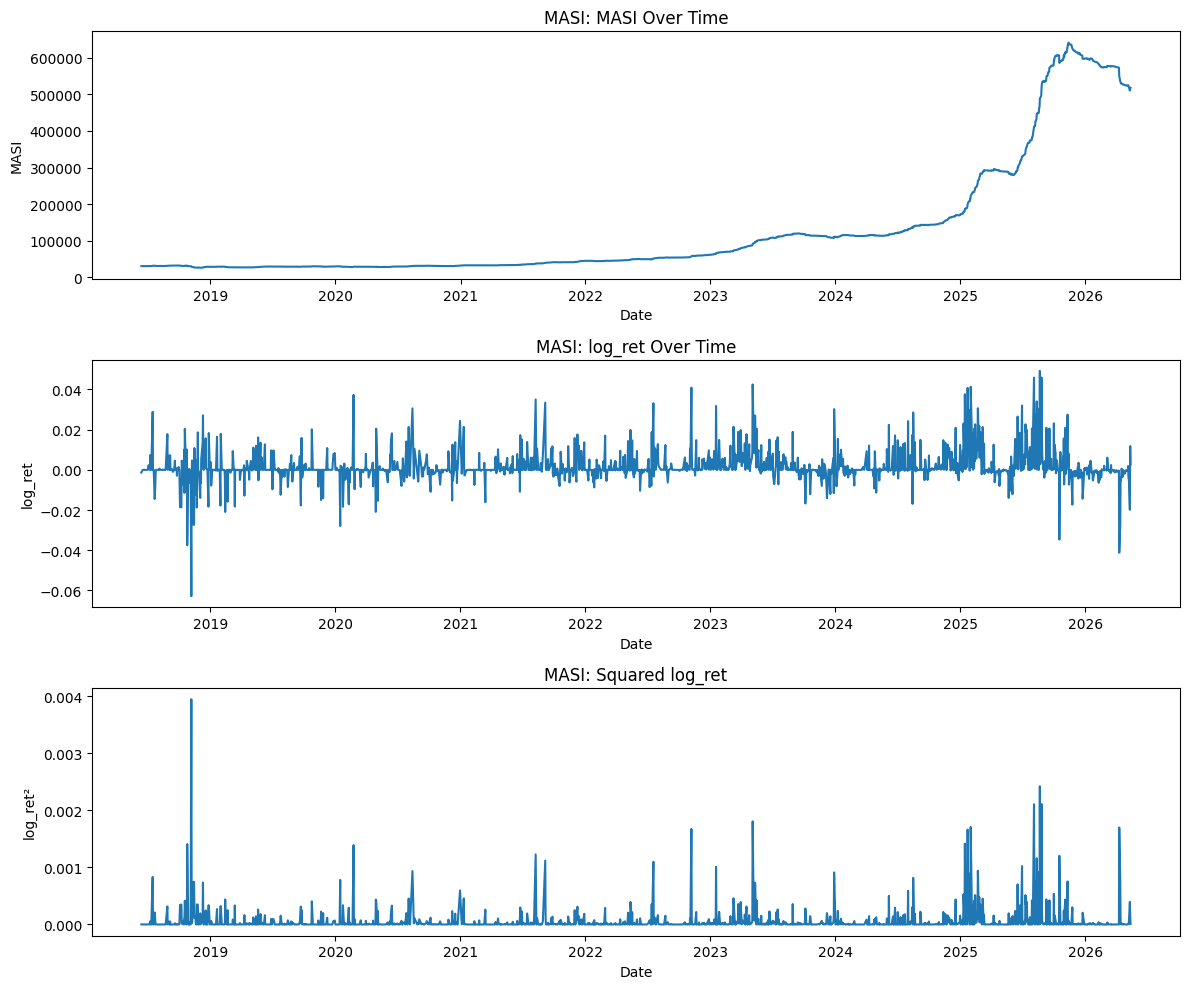

In [4]:
# Plot and save
fig = time_series_plots( data=masi_df, price_col="MASI", return_col="log_ret",title_prefix="MASI")
# fig.savefig("../figures/masi_time_series.svg", dpi = 600, bbox_inches="tight")


### **1.1.  Returns Distribution Plots**

<div style="background-color:#dbeafe; padding:10px; border-left:5px solid #2563eb;">
<b>Note:</b> Rice rule: $k = 2 \cdot n^{1/3}$ was used to determine number of bins for te histogram. 
</div>


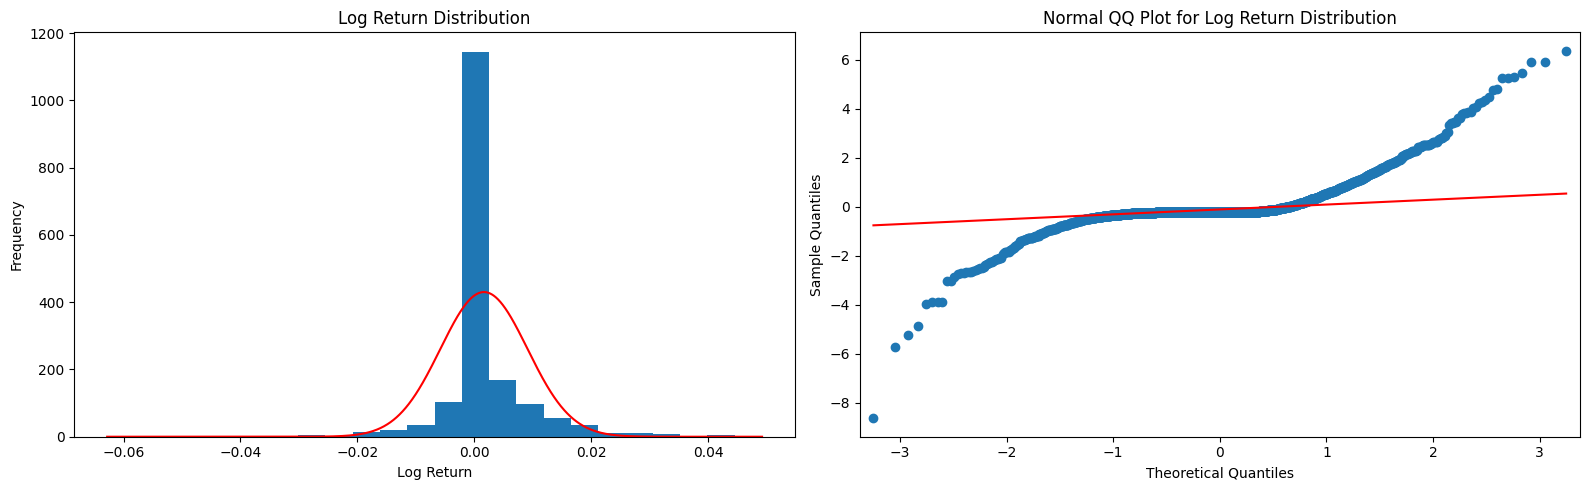

In [5]:
# Plot the distribution of the returns and save the fig.
fig2 = distribution_plots(masi_r)
# fig2.savefig( "../figures/ts_distr.png", dpi=600, bbox_inches="tight")

### **1.2.  MASI Performance Plots**

In [6]:
# yearly perfomance plots
masi_df["yearly_ret"] = (1 + masi_df["log_ret"]).groupby(masi_df.index.year).prod() - 1

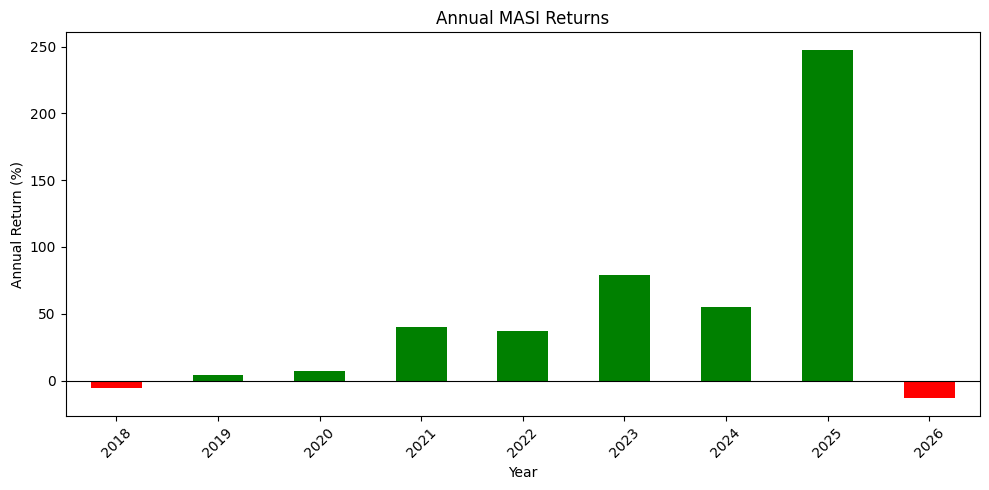

In [7]:
# Plot Annual Returns of MASI
annual_ret = plot_annual_returns(masi_df)
# plt.savefig("figures/annual_masi_returns.png",dpi=300,bbox_inches="tight"

## **2. Testing Stationality** 

In [8]:
stationarity_results = stationarity_tests(masi_r)
print(stationarity_results)

STATIONARITY TESTS
------------------------------------------
Augmented Dickey-Fuller (ADF)
Test statistic: -9.374161
p-value:        0.000000
Decision: Reject H0 — Series is stationary
------------------------------------------
Phillips-Perron (PP)
Test statistic: -46.407042
p-value:        0.000000
Decision: Reject H0 — Series is stationary
------------------------------------------
Final Stationarity Decision:
Series is stationary
              Test  Test Statistic       p-value  5% Critical Value  \
0              ADF       -9.374161  7.242534e-16          -2.863226   
1  Phillips-Perron      -46.407042  0.000000e+00          -2.863220   

                 Decision  
0  Reject H0 — Stationary  
1  Reject H0 — Stationary  


There is no need to difference the data therefore te order of $d$ is zero. The results were confirmed in the Handyan-Kandakar algoritm for model identification.

## **3. Model Specification**
### **3.1 ARMA Mean Model Selection** 

In [9]:
# Identify ARIMA order 
mean_model = auto_arima(
    masi_r,
    start_p=0,
    d=0,
    start_q=0,
    max_p=3,
    max_q=3,
    trace=True,
    with_intercept=True,
    return_valid_fits=True
)

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,0,0)[0] intercept   : AIC=-11986.202, Time=0.25 sec
 ARIMA(1,0,0)(0,0,0)[0] intercept   : AIC=-12021.890, Time=0.17 sec
 ARIMA(0,0,1)(0,0,0)[0] intercept   : AIC=-12012.438, Time=0.41 sec
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=-11907.001, Time=0.06 sec
 ARIMA(2,0,0)(0,0,0)[0] intercept   : AIC=-12073.944, Time=0.37 sec
 ARIMA(3,0,0)(0,0,0)[0] intercept   : AIC=-12113.603, Time=0.44 sec
 ARIMA(3,0,1)(0,0,0)[0] intercept   : AIC=-12111.032, Time=0.64 sec
 ARIMA(2,0,1)(0,0,0)[0] intercept   : AIC=-12176.080, Time=0.31 sec
 ARIMA(1,0,1)(0,0,0)[0] intercept   : AIC=-12185.710, Time=0.25 sec
 ARIMA(1,0,2)(0,0,0)[0] intercept   : AIC=-12171.343, Time=0.73 sec
 ARIMA(0,0,2)(0,0,0)[0] intercept   : AIC=-12047.719, Time=0.60 sec
 ARIMA(2,0,2)(0,0,0)[0] intercept   : AIC=-12182.597, Time=0.56 sec
 ARIMA(1,0,1)(0,0,0)[0]             : AIC=-12171.526, Time=0.57 sec

Best model:  ARIMA(1,0,1)(0,0,0)[0] intercept
Total fit time: 5.370 seco

In [10]:
# Fit ARIMA to returns 
mean_fit = SARIMAX( masi_r, order=(1, 0, 1), trend="c").fit()
print(mean_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                log_ret   No. Observations:                 1723
Model:               SARIMAX(1, 0, 1)   Log Likelihood                6096.855
Date:                Mon, 19 Oct 2026   AIC                         -12185.710
Time:                        20:26:22   BIC                         -12163.902
Sample:                             0   HQIC                        -12177.642
                               - 1723                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept   5.049e-05   2.74e-05      1.843      0.065    -3.2e-06       0.000
ar.L1          0.9650      0.009    110.185      0.000       0.948       0.982
ma.L1         -0.8712      0.018    -48.941      0.0

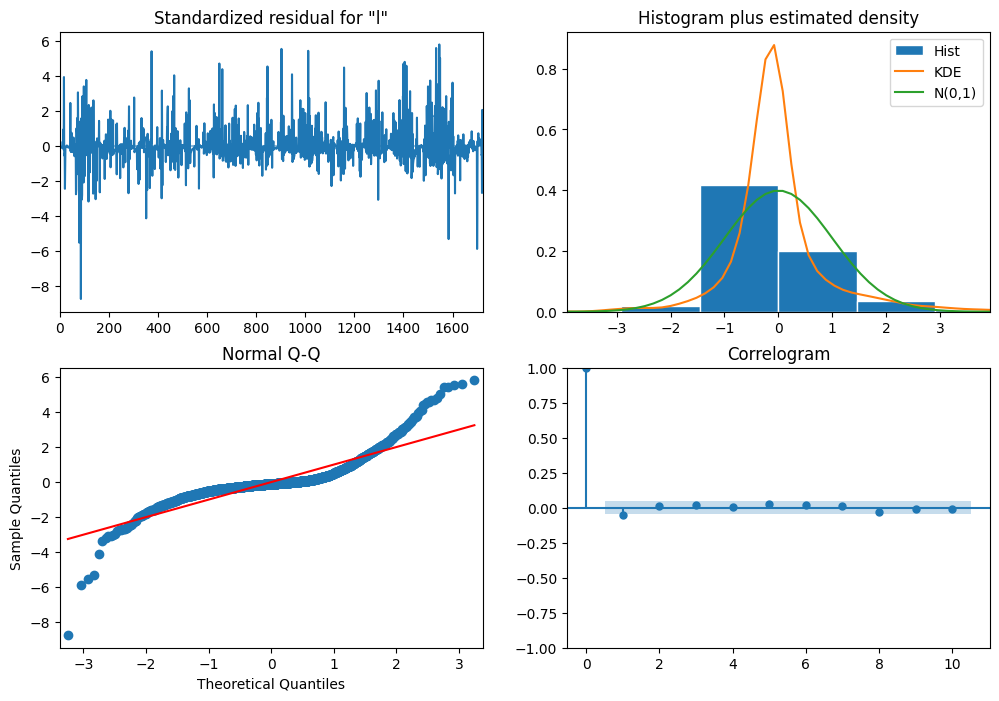

In [15]:
fig = mean_fit.plot_diagnostics(figsize=(12, 8))

fig.savefig(
    "figures/mean_model_diagnostics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
fig.savefig("figures/mean_model_diagnostics.png", dpi=300, bbox_inches="tight")

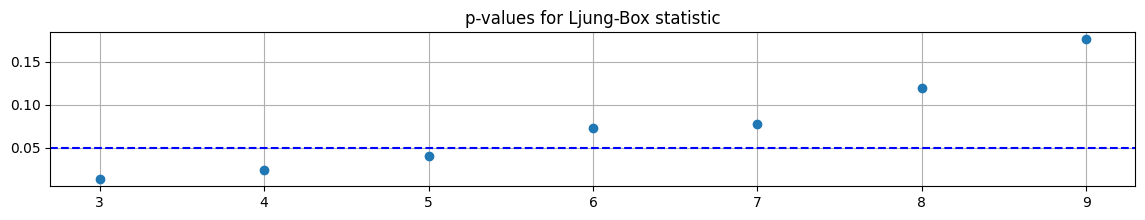

In [19]:
# Ljung-Box test for no serial correlation of standardized residuals
lb_test = mean_fit.test_serial_correlation(
    method="ljungbox", df_adjust=True, lags=None
)

# plot Ljung-Box test p-values and 0.05 significance line
plt.figure(figsize=(14, 2))
plt.plot(lb_test[0][1], linestyle="", marker="o")
plt.axhline(y=0.05, color="blue", linestyle="--")
plt.title("p-values for Ljung-Box statistic")
plt.grid()
plt.show()

In [20]:
# Obtain residuals of the mean equation 
resid = mean_fit.resid
acorr_ljungbox(resid.dropna(), lags=[5, 10, 20], return_df=True)

# Check if the mean is adequate

,lb_stat,lb_pvalue
5,7.410473,0.191858
10,10.220096,0.421400
20,21.334108,0.377707


In [21]:
# Check of cluster remains 
acorr_ljungbox(resid.dropna() ** 2, lags=[5, 10, 20], return_df=True)

,lb_stat,lb_pvalue
5,25.034048,1.372404e-04
10,83.893744,8.623333e-14
20,138.053479,1.183285e-19


In [22]:
# Test ARCH effects
arch_test = het_arch( resid.dropna(), nlags=10)

print("LM statistic:", arch_test[0])
print("LM p-value:", arch_test[1])

LM statistic: 66.88586997820215
LM p-value: 1.7635410902007537e-10


### **3.2 Fit the candidate models** 

In [23]:
# Compare candidate GARCH-family models
# returns = resid.dropna().astype(float)
returns = (100 * resid.dropna().astype(float)).replace([np.inf, -np.inf], np.nan).dropna()


models = {
    "GARCH(1,1)-Student-t": arch_model(returns, mean="Constant", vol="GARCH", p=1, q=1, dist="t"),
    "GARCH(1,1)-GED": arch_model(returns, mean="Constant", vol="GARCH", p=1, q=1, dist="ged"),
    "GARCH(1,1)-Skewed-t": arch_model(returns, mean="Constant", vol="GARCH", p=1, q=1, dist="skewt"),
    "EGARCH(1,1)-Student-t": arch_model(returns, mean="Constant", vol="EGARCH", p=1, o=1, q=1, dist="t"),
    "EGARCH(1,1)-GED": arch_model(returns, mean="Constant", vol="EGARCH", p=1, o=1, q=1, dist="ged"),
    "EGARCH(1,1)-Skewed-t": arch_model(returns, mean="Constant", vol="EGARCH", p=1, o=1, q=1, dist="skewt"),
    "GJR-GARCH(1,1)-Student-t": arch_model(returns, mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="t"),
    "GJR-GARCH(1,1)-Skewed-t": arch_model(returns, mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="skewt"),
    # "APARCH(1,1)-Student-t": arch_model(returns, mean="Constant", vol="APARCH", p=1, o=1, q=1, power=2.0, dist="t"),
    # "APARCH(1,1)-Skewed-t": arch_model(returns, mean="Constant", vol="APARCH", p=1, o=1, q=1, power=2.0, dist="skewt"),
}

fits = {}

for name, model in models.items():
    fits[name] = model.fit(disp="off")
    print(f"\n{'_' * 70}\n{name}\n{'_' * 70}")
    print(fits[name].summary())


______________________________________________________________________
GARCH(1,1)-Student-t
______________________________________________________________________
                        Constant Mean - GARCH Model Results                         
Dep. Variable:                         None   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -1073.99
Distribution:      Standardized Student's t   AIC:                           2157.98
Method:                  Maximum Likelihood   BIC:                           2185.24
                                              No. Observations:                 1723
Date:                      Mon, Oct 19 2026   Df Residuals:                     1722
Time:                              20:35:22   Df Model:                            1
                                  Mean Model                           

In [24]:
comparison = pd.DataFrame({
    "Log-Likelihood": {name: fit.loglikelihood for name, fit in fits.items()},
    "AIC": {name: fit.aic for name, fit in fits.items()},
    "BIC": {name: fit.bic for name, fit in fits.items()}
})

comparison = comparison.sort_values("AIC")
comparison.index.name = "Student-t-Distribution"

comparison

,Log-Likelihood,AIC,BIC
Student-t-Distribution,,,
"EGARCH(1,1)-Skewed-t",-947.608573,1909.217145,1947.379901
"GJR-GARCH(1,1)-Skewed-t",-1007.069316,2028.138633,2066.301388
"GARCH(1,1)-Skewed-t",-1024.047896,2060.095792,2092.806726
"EGARCH(1,1)-Student-t",-1025.740373,2063.480746,2096.191680
"GJR-GARCH(1,1)-Student-t",-1067.209354,2146.418707,2179.129641
"GARCH(1,1)-Student-t",-1073.990245,2157.980489,2185.239600
"EGARCH(1,1)-GED",-1187.617205,2387.234409,2419.945343
"GARCH(1,1)-GED",-1193.504450,2397.008900,2424.268011


### **3.4 Model Diagnostics** 

In [25]:
egarch_skewt_fit = fits["EGARCH(1,1)-Skewed-t"] # the selected model 

In [26]:
# Diagnostic tests for EGARCH(1,1) Model with skewed Student's t White Noise
print("EGARCH(1,1) Model with skewedStudentsT White Noise\n")

# Ljung-Box test and the Box-Pierce test
print("Ljung-Box and Box-Pierce tests on standardized residuals")
print(acorr_ljungbox(egarch_skewt_fit.std_resid, boxpierce=True))

print("\nLjung-Box and Box-Pierce tests on standardized squared residuals")
print(acorr_ljungbox(egarch_skewt_fit.std_resid**2, boxpierce=True))

# ARCH LM test for conditional heteroskedasticity
print("\nARCH LM test for conditional heteroskedasticity for")
print(egarch_skewt_fit.arch_lm_test(standardized=True))

EGARCH(1,1) Model with skewedStudentsT White Noise

Ljung-Box and Box-Pierce tests on standardized residuals
     lb_stat  lb_pvalue   bp_stat  bp_pvalue
1   2.058247   0.151384  2.054668   0.151740
2   2.281914   0.319513  2.277816   0.320168
3   3.356255   0.339889  3.349042   0.340875
4   5.286470   0.259146  5.272544   0.260458
5   5.395308   0.369562  5.380941   0.371178
6   6.542846   0.365198  6.523156   0.367201
7   6.770351   0.453176  6.749474   0.455422
8   6.950259   0.542009  6.928340   0.544384
9   7.784225   0.556029  7.756988   0.558809
10  7.868115   0.641718  7.840294   0.644433

Ljung-Box and Box-Pierce tests on standardized squared residuals
     lb_stat  lb_pvalue   bp_stat  bp_pvalue
1   0.014257   0.904955  0.014233   0.905037
2   0.083617   0.959053  0.083432   0.959142
3   0.207543   0.976363  0.206998   0.976452
4   0.268176   0.991775  0.267421   0.991819
5   0.380923   0.995839  0.379710   0.995870
6   0.536106   0.997371  0.534173   0.997397
7   0.570545   

In [27]:
masi_r = masi_r.dropna().astype(float)
train  = masi_r[masi_r.index < "2026-01-01"]
y      = train * 100
N_OBS  = len(y)

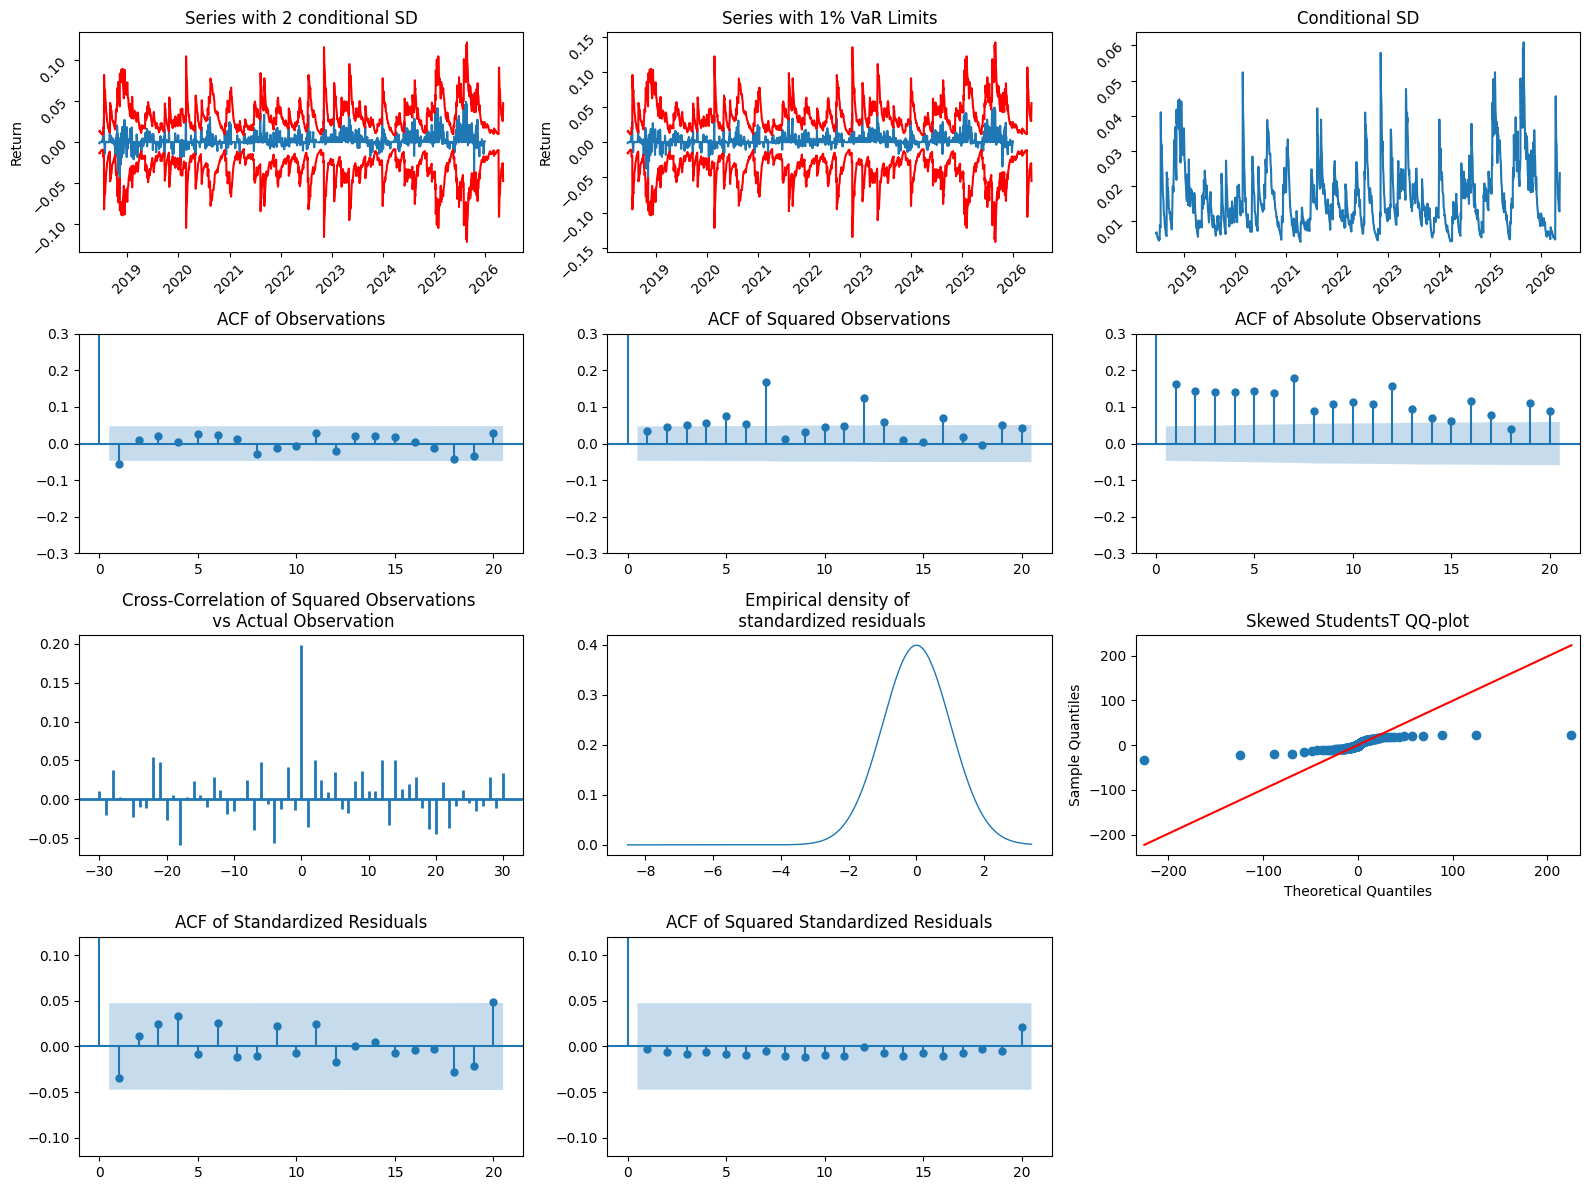

In [28]:
# Model Diagnostic Plots for the EGARCH(1,1) Model with Skewed Student's t White Noise
fig, ax = plt.subplots(4, 3, figsize=(16, 12))

# Figure Row 1 Column 1
ax[0, 0].plot(train)
ax[0, 0].plot(2.0 * egarch_skewt_fit.conditional_volatility / 100.0, c="r")
ax[0, 0].plot(-2.0 * egarch_skewt_fit.conditional_volatility / 100.0, c="r")
ax[0, 0].tick_params(labelrotation=45)
ax[0, 0].set_title("Series with 2 conditional SD")
ax[0, 0].set_ylabel("Return")

# Figure Row 1 Column 2
VaR_1 = stats.t(df=len(train) - 1).ppf(0.99)
ax[0, 1].plot(train)
ax[0, 1].plot(VaR_1 * egarch_skewt_fit.conditional_volatility / 100.0, c="r")
ax[0, 1].plot(-VaR_1 * egarch_skewt_fit.conditional_volatility / 100.0, c="r")
ax[0, 1].tick_params(labelrotation=45)
ax[0, 1].set_title("Series with 1% VaR Limits")
ax[0, 1].set_ylabel("Return")

# Figure Row 1 Column 3
ax[0, 2].plot(egarch_skewt_fit.conditional_volatility / 100.0)
ax[0, 2].set_title("Conditional SD")
ax[0, 2].tick_params(labelrotation=45)

# Figure Row 2 Column 1
sm.graphics.tsa.plot_acf(egarch_skewt_fit.resid / 100.0, lags=20, ax=ax[1, 0])
ax[1, 0].set_title("ACF of Observations")
ax[1, 0].set_ylim([-0.3, 0.3])

# Figure Row 2 Column 2
sm.graphics.tsa.plot_acf(egarch_skewt_fit.resid**2, lags=20, ax=ax[1, 1])
ax[1, 1].set_title("ACF of Squared Observations")
ax[1, 1].set_ylim([-0.3, 0.3])

# Figure Row 2 Column 3
sm.graphics.tsa.plot_acf(np.abs(egarch_skewt_fit.resid), lags=20, ax=ax[1, 2])
ax[1, 2].set_title("ACF of Absolute Observations")
ax[1, 2].set_ylim([-0.3, 0.3])

# Figure Row 3 Column 1
ax[2, 0].xcorr(
    egarch_skewt_fit.resid**2,
    egarch_skewt_fit.resid,
    usevlines=True,
    maxlags=30,
    normed=True,
    lw=2,
)
ax[2, 0].set_title("Cross-Correlation of Squared Observations \n vs Actual Observation")

# Figure Row 3 Column 2
standardized_residuals = egarch_skewt_fit.std_resid
min_val = np.min(standardized_residuals)
max_val = np.max(standardized_residuals)
empirical_density = np.linspace(min_val, max_val, len(standardized_residuals))
ax[2, 1].plot(empirical_density, stats.norm.pdf(empirical_density), lw=1)
ax[2, 1].set_title("Empirical density of \n standardized residuals")

# Figure Row 3 Column 3
sm.qqplot(egarch_skewt_fit.resid, stats.t, fit=True, line="q", ax=ax[2, 2])
ax[2, 2].set_title("Skewed StudentsT QQ-plot")

# Figure Row 4 Column 1
sm.graphics.tsa.plot_acf(egarch_skewt_fit.std_resid, lags=20, ax=ax[3, 0])
ax[3, 0].set_title("ACF of Standardized Residuals")
ax[3, 0].set_ylim([-0.12, 0.12])

# Figure Row 4 Column 2
sm.graphics.tsa.plot_acf((egarch_skewt_fit.std_resid) ** 2, lags=20, ax=ax[3, 1])
ax[3, 1].set_title("ACF of Squared Standardized Residuals")
ax[3, 1].set_ylim([-0.12, 0.12])

ax[3, 2].axis("off")
fig.tight_layout()
plt.show()

In [29]:
fig.savefig("egarch_diagnostics.png", dpi=300, bbox_inches="tight")

## 2. Models

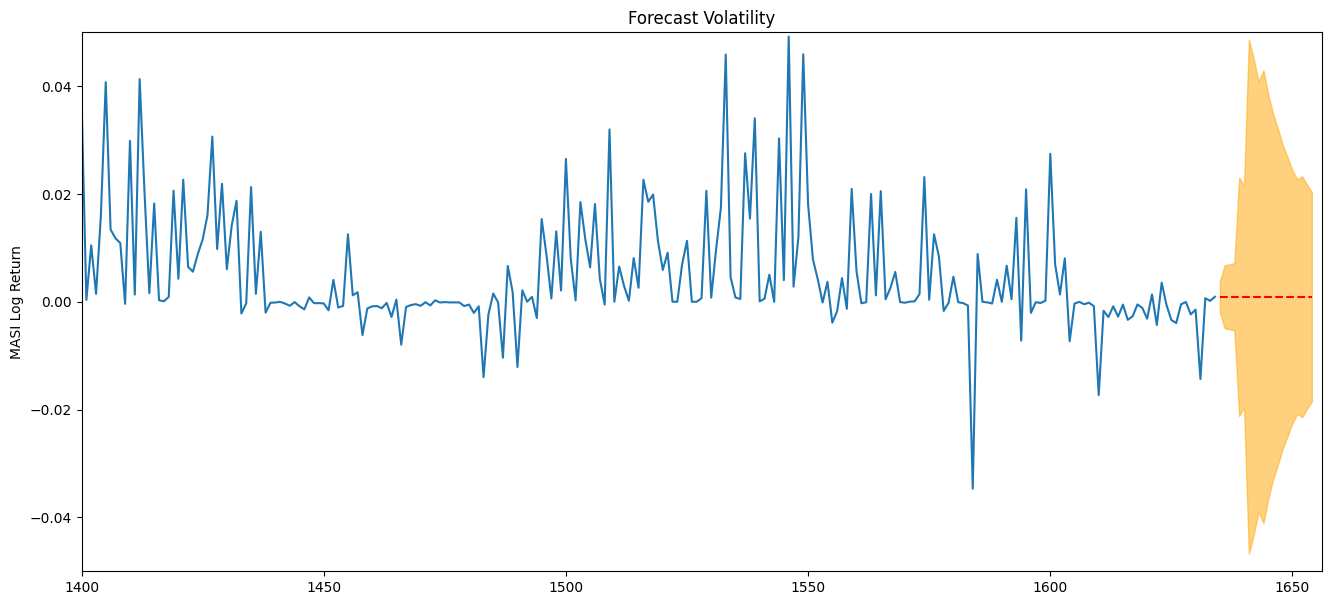

In [37]:
# 20 Steps Ahead Forecast for EGARCH(1,1) Model with Skewed Student's t White Noise

# set horizon and forecast
horizon = 20
egarch_forecast = egarch_skewt_fit.forecast(
    reindex=False, horizon=horizon, method="simulation"
)

# reindex data
masi_rr = train.copy()
masi_rr.index = list(range(len(masi_rr)))

# forecast mean
forc_mean = pd.Series(egarch_forecast.mean.dropna().squeeze())
forc_mean.index = list(range(len(masi_rr), len(masi_rr) + horizon))

# volatility forecast
variance_fct = pd.DataFrame(data={"Forecast": egarch_forecast.variance.values[0]})
variance_fct.index = list(range(len(masi_rr), len(masi_rr) + horizon))
std_fct = [(variance_fct.values[i] * (i + 1)) ** 0.5 for i in range(len(variance_fct))]
volatility_fct = pd.DataFrame(np.sqrt(std_fct))

# upper/lower bands
upper_band = masi_rr.values[-1] * (1.0 + 2 * volatility_fct)
upper_band.index = variance_fct.index
lower_band = masi_rr.values[-1] * (1.0 - 2 * volatility_fct)
lower_band.index = variance_fct.index

# Plot
plt.figure(figsize=(16, 7))
plt.xlim(1400, len(masi_rr) + 21)
plt.ylim(-0.05, 0.05)
masi_rr.plot(ylabel="MASI Log Return", title="Forecast Volatility")
plt.plot((upper_band + lower_band) / 2, "r--")
plt.fill_between(
    upper_band.index.tolist(),
    upper_band.values.T[0],
    lower_band.values.T[0],
    color="orange",
    alpha=0.5,
)
plt.savefig("egarch_20step_forecast.png", dpi=300, bbox_inches="tight")
plt.show()

In [31]:
plt.savefig("egarch_20step_forecast.png", dpi=300, bbox_inches="tight")

<Figure size 1600x900 with 0 Axes>

In [32]:
# 2.6 Sign Bias Test
z = pd.Series(egarch_skewt_fit.std_resid).dropna()

z_lag = z.shift(1)
sign_neg = (z_lag < 0).astype(float)
sign_pos = (z_lag >= 0).astype(float)

data = pd.DataFrame({
    "z2": z**2,
    "sign_bias": sign_neg,
    "negative_size_bias": sign_neg * z_lag,
    "positive_size_bias": sign_pos * z_lag
}).dropna()

X = sm.add_constant(data[["sign_bias", "negative_size_bias", "positive_size_bias"]])
fit = sm.OLS(data["z2"], X).fit()

print(fit.summary())
print("\nJoint test: no sign or size bias")
print(fit.f_test("sign_bias = negative_size_bias = positive_size_bias = 0"))

                            OLS Regression Results                            
Dep. Variable:                     z2   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                 -0.001
Method:                 Least Squares   F-statistic:                    0.5155
Date:                Mon, 19 Oct 2026   Prob (F-statistic):              0.672
Time:                        20:35:27   Log-Likelihood:                -3585.3
No. Observations:                1722   AIC:                             7179.
Df Residuals:                    1718   BIC:                             7200.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  0.2036      0

In [33]:
print(egarch_skewt_fit.params)

mu          0.016720
omega       0.439498
alpha[1]    0.773602
gamma[1]    0.235307
beta[1]     0.973961
eta         2.050000
lambda      0.301683
Name: params, dtype: float64


In [34]:
egarch_skewt_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Constant Mean - EGARCH Model Results                          
=========================================================================================
Dep. Variable:                              None   R-squared:                       0.000
Mean Model:                        Constant Mean   Adj. R-squared:                  0.000
Vol Model:                                EGARCH   Log-Likelihood:               -947.609
Distribution:      Standardized Skew Student's t   AIC:                           1909.22
Method:                       Maximum Likelihood   BIC:                           1947.38
                                                   No. Observations:                 1723
Date:                           Mon, Oct 19 2026   Df Residuals:                     1722
Time:                                   20:35:22   Df Model:                            1
                                 Mean Model                                 
============================================================================
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu             0.0167  5.223e-04     32.014 6.995e-225 [1.570e-02,1.774e-02]
                              Volatility Model                             
===========================================================================
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
omega          0.4395      0.271      1.621      0.105 [-9.175e-02,  0.971]
alpha[1]       0.7736      0.328      2.361  1.822e-02    [  0.131,  1.416]
gamma[1]       0.2353  9.497e-02      2.478  1.322e-02  [4.918e-02,  0.421]
beta[1]        0.9740  7.081e-03    137.549      0.000    [  0.960,  0.988]
                              Distribution                              
========================================================================
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
eta            2.0500  3.900e-02     52.559      0.000 [  1.974,  2.126]
lambda         0.3017  1.771e-02     17.035  4.519e-65 [  0.267,  0.336]
========================================================================

Covariance estimator: robust
"""